# Integer Linear Programming: Formulations, Algorithms, and Applications

Integer programming determines discrete decisions such as whether to fund a project, open a service, activate a supplier, or choose a route. Every application below starts with the physical decision problem, states its **individual numerical equations**, and then checks the result computationally. Algorithm sections display the operations used to reach their solutions.

**Notation.** Binary variables satisfy $x_j\in\{0,1\}$; general integer variables satisfy $x_j\in\mathbb Z_{\ge0}$. Dollars and capacities are reported in the units defined for each problem. Small examples are instructional; larger combinatorial problems are solved with optimized libraries.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds, linprog
from itertools import combinations, permutations
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)
pd.set_option('display.max_columns',25)

def solve_milp(c, A, lb, ub, integrality=None, lower=None, upper=None):
    c=np.asarray(c,dtype=float); A=np.asarray(A,dtype=float)
    if integrality is None: integrality=np.ones(len(c))
    if lower is None: lower=np.zeros(len(c))
    if upper is None: upper=np.full(len(c),np.inf)
    r=milp(c,integrality=integrality,bounds=Bounds(lower,upper),constraints=LinearConstraint(A,lb,ub),options={'mip_rel_gap':1e-10})
    assert r.success,r.message
    return r

## 1. Capital budgeting — binary project selection

**Problem.** A firm is evaluating five investment projects over three years. Each project generates a specified expected return and requires funds in each year. The firm has at most **$25 million in each of the three years**. A project must be selected in its entirety or not at all. Which combination maximizes total return?

| Project | Year 1 expense | Year 2 expense | Year 3 expense | Return |
|---|---:|---:|---:|---:|
| 1 | 5 | 1 | 8 | 20 |
| 2 | 4 | 7 | 10 | 40 |
| 3 | 3 | 9 | 2 | 20 |
| 4 | 7 | 4 | 1 | 15 |
| 5 | 8 | 6 | 10 | 30 |

*All amounts are in millions of dollars.* Let $x_j=1$ when project $j$ is selected and $x_j=0$ otherwise.

**Complete numerical formulation**

$$
\max z=20x_1+40x_2+20x_3+15x_4+30x_5
$$

$$
\begin{aligned}
5x_1+4x_2+3x_3+7x_4+8x_5&\le25 &&\text{Year 1}\\
x_1+7x_2+9x_3+4x_4+6x_5&\le25 &&\text{Year 2}\\
8x_1+10x_2+2x_3+x_4+10x_5&\le25 &&\text{Year 3}
\end{aligned}
$$

$$
x_1,x_2,x_3,x_4,x_5\in\{0,1\}.
$$

**How exhaustive enumeration works.** A binary selection of five projects has $2^5=32$ possible subsets. For each subset, compute the three-year cost totals, reject any subset exceeding a yearly budget, calculate the total return for the remaining subsets, and select the greatest. This provides an independently checkable optimum for this small example.

### Exhaustive enumeration

**PSEUDOCODE — executable algorithm logic**

**Input:** profit vector, three annual expenditure vectors, and the three annual budgets. **Output:** the best feasible binary project vector and its total return. Every project subset is evaluated; therefore this method is an exact benchmark for five projects, although its $2^n$ search grows quickly.

```text
# PSEUDOCODE (NOT PYTHON)
ENUMERATE_PROJECTS(profit, expense, budget):
    best_return <- -infinity
    best_selection <- none
    for mask from 0 through 2^n - 1:
        decode mask into binary selection x[1..n]
        spending <- expense * x
        if spending[t] <= budget[t] for every year t:
            value <- sum(profit[j] * x[j] for every project j)
            if value > best_return:
                best_return <- value
                best_selection <- x
    return best_selection, best_return
```

**Worked iteration logic:** decode a binary candidate, calculate its three annual expenses, discard it if any exceeds 25, or compare its return with the incumbent. The following cell performs these operations for all 32 combinations and displays the feasible candidates.

In [2]:
year=np.array([[5,4,3,7,8],[1,7,9,4,6],[8,10,2,1,10]],dtype=float)
profit=np.array([20,40,20,15,30],dtype=float)
records=[]
for bits in range(32):
    x=np.array([(bits>>i)&1 for i in range(5)])
    use=year@x
    records.append({'Selection':''.join(map(str,x)),'Year 1':use[0],'Year 2':use[1],'Year 3':use[2],
                    'Return':profit@x,'Feasible':bool(np.all(use<=25))})
all_projects=pd.DataFrame(records)
display(all_projects.sort_values(['Feasible','Return'],ascending=False).head(12))
r=solve_milp(-profit,year,[-np.inf]*3,[25]*3,upper=np.ones(5))
print('Chosen projects:',np.flatnonzero(r.x>.5)+1,'return (million $):',-r.fun)
assert np.isclose(-r.fun,all_projects.loc[all_projects.Feasible,'Return'].max())
lp=linprog(-profit,A_ub=year,b_ub=np.full(3,25),bounds=[(0,1)]*5,method='highs')
print('LP relaxation:',np.round(lp.x,4),'upper bound:',round(-lp.fun,4))

,Selection,Year 1,Year 2,Year 3,Return,Feasible
15,11110,19.0,21.0,21.0,95.0,True
22,01101,15.0,22.0,22.0,90.0,True
26,01011,19.0,17.0,21.0,85.0,True
29,10111,23.0,20.0,21.0,85.0,True
7,11100,12.0,17.0,20.0,80.0,True
11,11010,16.0,12.0,19.0,75.0,True
14,01110,14.0,20.0,13.0,75.0,True
18,01001,12.0,13.0,20.0,70.0,True
21,10101,16.0,16.0,20.0,70.0,True
25,10011,20.0,11.0,19.0,65.0,True


Chosen projects: [1 2 3 4] return (million $): 95.0
LP relaxation: [0.5789 1.     1.     1.     0.7368] upper bound: 108.6842


### Full enumeration trace — evaluate all 32 project

For candidate $(x_1,\ldots,x_5)$ compute the **three annual spending totals** $b_t=\sum_{j=1}^5 a_{tj}x_j$, followed by the return $z=\sum_{j=1}^5p_jx_j$. The candidate is feasible precisely when $b_1,b_2,b_3\le25$. The code below shows **all 32 candidates**, including rejected combinations, and the incumbent after each feasible check.

**Worked first calculations:** For $(0,0,0,0,0)$, spending is $(0,0,0)$ and return is $0$. For $(1,0,0,0,0)$, spending is $(5,1,8)$ and return is $20$. For $(1,1,0,0,0)$, spending is $(9,8,18)$ and return is $60$. Every remaining candidate is checked with exactly the same formulas.

In [3]:
budget_trace=[]; incumbent=-np.inf; selected=None
for bits in range(32):
    x=np.array([(bits>>i)&1 for i in range(5)], dtype=int)
    spending=year@x; z=float(profit@x)
    feasible=bool(np.all(spending<=25))
    decision='Reject: budget exceeded'
    if feasible:
        if z>incumbent:
            incumbent=z;selected=x.copy();decision='Feasible: NEW incumbent'
        else: decision='Feasible: retain incumbent'
    budget_trace.append({'Step':bits+1,'(x1,x2,x3,x4,x5)':tuple(x),
        'Year 1 calculation':' + '.join(str(int(year[0,j])) for j in range(5) if x[j]) or '0',
        'Year 1':int(spending[0]),'Year 2':int(spending[1]),'Year 3':int(spending[2]),
        'Return':int(z),'Decision':decision,'Best feasible return so far':incumbent if np.isfinite(incumbent) else '—'})
display(pd.DataFrame(budget_trace))
assert np.isclose(incumbent,-r.fun)
print('Final incumbent:',int(incumbent),'million; chosen vector:',selected)


,Step,"(x1,x2,x3,x4,x5)",Year 1 calculation,Year 1,Year 2,Year 3,Return,Decision,Best feasible return so far
0,1,"(0, 0, 0, 0, 0)",0,0,0,0,0,Feasible: NEW incumbent,0.0
1,2,"(1, 0, 0, 0, 0)",5,5,1,8,20,Feasible: NEW incumbent,20.0
2,3,"(0, 1, 0, 0, 0)",4,4,7,10,40,Feasible: NEW incumbent,40.0
3,4,"(1, 1, 0, 0, 0)",5 + 4,9,8,18,60,Feasible: NEW incumbent,60.0
4,5,"(0, 0, 1, 0, 0)",3,3,9,2,20,Feasible: retain incumbent,60.0
5,6,"(1, 0, 1, 0, 0)",5 + 3,8,10,10,40,Feasible: retain incumbent,60.0
6,7,"(0, 1, 1, 0, 0)",4 + 3,7,16,12,60,Feasible: retain incumbent,60.0
7,8,"(1, 1, 1, 0, 0)",5 + 4 + 3,12,17,20,80,Feasible: NEW incumbent,80.0
8,9,"(0, 0, 0, 1, 0)",7,7,4,1,15,Feasible: retain incumbent,80.0
9,10,"(1, 0, 0, 1, 0)",5 + 7,12,5,9,35,Feasible: retain incumbent,80.0


Final incumbent: 95 million; chosen vector: [1 1 1 1 0]


**Interpretation.** Integer constraints prevent fractional funding of a yes/no project. The continuous relaxation supplies an **upper bound** on maximum attainable return, not a valid project list. Rounding fractional values without checking the budgets can violate a yearly restriction.

## 2. Set covering — locating the fewest services

**Problem.** Ten meters must communicate with at least one wireless receiver. Eight candidate receiver locations cover the meter sets shown below. Choose the smallest number of receiver sites so that all ten meters are covered. This is a set-covering model adapted from the receiver-coverage data in the chapter.

| Receiver | Meters covered |
|---|---|
| 1 | 1, 2, 3 |
| 2 | 2, 3, 9 |
| 3 | 5, 6, 7 |
| 4 | 7, 9, 10 |
| 5 | 3, 6, 8 |
| 6 | 1, 4, 7, 9 |
| 7 | 4, 5, 9 |
| 8 | 1, 4, 8 |

Let $y_j=1$ if receiver $j$ is installed. Each meter constraint requires one or more covering receivers.

$$
\min z=y_1+y_2+y_3+y_4+y_5+y_6+y_7+y_8.
$$

$$
\begin{aligned}
y_1+y_6+y_8&\ge1 &&\text{Meter 1}\\
y_1+y_2&\ge1 &&\text{Meter 2}\\
y_1+y_2+y_5&\ge1 &&\text{Meter 3}\\
y_6+y_7+y_8&\ge1 &&\text{Meter 4}\\
y_3+y_7&\ge1 &&\text{Meter 5}\\
y_3+y_5&\ge1 &&\text{Meter 6}\\
y_3+y_4+y_6&\ge1 &&\text{Meter 7}\\
y_5+y_8&\ge1 &&\text{Meter 8}\\
y_2+y_4+y_6+y_7&\ge1 &&\text{Meter 9}\\
y_4&\ge1 &&\text{Meter 10}
\end{aligned}
$$

$$
y_j\in\{0,1\},\quad j=1,\ldots,8.
$$

**Algorithm.** A binary MILP solver branches on installation choices and prunes subproblems whose LP bounds cannot improve the best covering solution. For this eight-variable example, we also enumerate all $2^8$ subsets and verify coverage explicitly.

### Set covering

**PSEUDOCODE — executable algorithm logic**

**Input:** a coverage matrix $a_{ij}$ equal to 1 when receiver $j$ covers meter $i$. **Output:** a minimum-cardinality receiver set covering all ten meters. Enumeration independently checks the MILP solution. For each installation vector $y$, calculate coverage of meter $i$ as $
\sum_j a_{ij}y_j
$; feasibility requires this quantity to be at least 1 for every meter.

```text
# PSEUDOCODE (NOT PYTHON)
ENUMERATE_COVERS(coverage):
    best_count <- infinity
    best_sites <- none
    for every binary vector y of length number_of_sites:
        count <- sum(y)
        if count >= best_count:
            continue                     # cannot improve incumbent
        feasible <- true
        for each meter i:
            if sum(coverage[i,j] * y[j] for every site j) < 1:
                feasible <- false
                break
        if feasible:
            best_count <- count
            best_sites <- y
    return best_sites, best_count
```

**Decision rule:** a candidate is accepted only if all ten meter constraints hold. The output identifies the selected receivers and explicitly verifies each meter's coverage.

In [4]:
covers=[{1,2,3},{2,3,9},{5,6,7},{7,9,10},{3,6,8},{1,4,7,9},{4,5,9},{1,4,8}]
C=np.array([[int(k in site) for site in covers] for k in range(1,11)])
print('Coverage matrix (rows meters, columns receivers):')
display(pd.DataFrame(C,index=[f'Meter {i}' for i in range(1,11)],columns=[f'R{j}' for j in range(1,9)]))
sc=solve_milp(np.ones(8),C,np.ones(10),np.full(10,np.inf),upper=np.ones(8))
chosen=np.flatnonzero(sc.x>.5)+1
print('Chosen receivers:',chosen,'count:',len(chosen))
print('Coverage by meter:',C@(sc.x>.5).astype(int))
opt_subsets=[]
for k in range(1,9):
    opt_subsets=[v for v in combinations(range(8),k) if np.all(C[:,v].sum(axis=1)>=1)]
    print('Checked subsets of size',k,'found feasible:',len(opt_subsets))
    if opt_subsets: break
assert len(chosen)==k

Coverage matrix (rows meters, columns receivers):


,R1,R2,R3,R4,R5,R6,R7,R8
Meter 1,1,0,0,0,0,1,0,1
Meter 2,1,1,0,0,0,0,0,0
Meter 3,1,1,0,0,1,0,0,0
Meter 4,0,0,0,0,0,1,1,1
Meter 5,0,0,1,0,0,0,1,0
Meter 6,0,0,1,0,1,0,0,0
Meter 7,0,0,1,1,0,1,0,0
Meter 8,0,0,0,0,1,0,0,1
Meter 9,0,1,0,1,0,1,1,0
Meter 10,0,0,0,1,0,0,0,0


Chosen receivers: [1 3 4 8] count: 4
Coverage by meter: [2 1 1 1 1 1 2 1 1 1]
Checked subsets of size 1 found feasible: 0
Checked subsets of size 2 found feasible: 0
Checked subsets of size 3 found feasible: 0
Checked subsets of size 4 found feasible: 3


### Full set-covering search — evaluate candidate receiver subsets

A candidate subset $S$ covers meter $i$ when $\sum_{j\in S}a_{ij}\ge1$. The algorithm tests subsets in increasing cardinality $k=0,1,\ldots,8$; within each $k$ it visits combinations in lexicographic order. For each subset the output shows the **covered meters, uncovered meters, feasibility, and incumbent**. We stop only after completing the first cardinality for which a feasible cover exists, so smaller covers have been exhaustively ruled out.

For example, $S=\{R_1\}$ covers meters $\{1,2,3\}$ and leaves meters $\{4,5,6,7,8,9,10\}$ uncovered. Every subsequent subset is checked using the same explicit meter-by-meter coverage rule.

In [5]:
cover_trials=[]; best_cover=None
for ksize in range(9):
    for sub in combinations(range(8),ksize):
        counts=C[:,list(sub)].sum(axis=1) if sub else np.zeros(10,dtype=int)
        missing=[i+1 for i,v in enumerate(counts) if v<1]
        ok=not missing
        if ok and best_cover is None: best_cover=sub
        cover_trials.append({'Step':len(cover_trials)+1,'Subset':','.join(f'R{i+1}' for i in sub) or 'None',
            'Size':ksize,'Covered meters':','.join(str(i+1) for i,v in enumerate(counts) if v>=1) or 'None',
            'Uncovered meters':','.join(map(str,missing)) or 'None','Feasible':ok,
            'Decision':'Feasible minimum-size candidate' if ok else 'Reject: uncovered meter(s)'})
    if best_cover is not None:break
print('Complete search trace through first feasible cardinality:')
display(pd.DataFrame(cover_trials))
print('Minimum receivers:',len(best_cover),'first optimum:',[i+1 for i in best_cover])
assert len(best_cover)==len(chosen)


Complete search trace through first feasible cardinality:


,Step,Subset,Size,Covered meters,Uncovered meters,Feasible,Decision
0,1,None,0,None,"1,2,3,4,5,6,7,8,9,10",False,Reject: uncovered meter(s)
1,2,R1,1,"1,2,3","4,5,6,7,8,9,10",False,Reject: uncovered meter(s)
2,3,R2,1,"2,3,9","1,4,5,6,7,8,10",False,Reject: uncovered meter(s)
3,4,R3,1,"5,6,7","1,2,3,4,8,9,10",False,Reject: uncovered meter(s)
4,5,R4,1,"7,9,10","1,2,3,4,5,6,8",False,Reject: uncovered meter(s)
...,...,...,...,...,...,...,...
158,159,"R4,R5,R6,R7",4,"1,3,4,5,6,7,8,9,10",2,False,Reject: uncovered meter(s)
159,160,"R4,R5,R6,R8",4,"1,3,4,6,7,8,9,10","2,5",False,Reject: uncovered meter(s)
160,161,"R4,R5,R7,R8",4,"1,3,4,5,6,7,8,9,10",2,False,Reject: uncovered meter(s)
161,162,"R4,R6,R7,R8",4,"1,4,5,7,8,9,10","2,3,6",False,Reject: uncovered meter(s)


Minimum receivers: 4 first optimum: [1, 3, 4, 8]


## 3. Fixed-charge decisions — activate a supplier before using it

**Problem.** Three long-distance providers charge a fixed monthly subscription plus a variable cost per calling minute. Exactly 200 minutes must be purchased. Minutes may be split, but a subscription is paid only for an activated provider.

| Provider | Fixed fee ($) | Variable cost ($/min) |/
|---|---:|---:|
| MaBell | 16 | 0.25 |
| PaBell | 25 | 0.21 |
| BabyBell | 18 | 0.22 |

Let $x_j$ denote purchased minutes from provider $j$ and $y_j\in\{0,1\}$ indicate activation. The implication $x_j>0\Rightarrow y_j=1$ is enforced by $x_j\le200y_j$.

$$
\min z=0.25x_1+0.21x_2+0.22x_3+16y_1+25y_2+18y_3.
$$

$$
\begin{aligned}
x_1+x_2+x_3&=200 &&\text{Minutes required}\\
x_1-200y_1&\le0 &&\text{MaBell activation}\\
x_2-200y_2&\le0 &&\text{PaBell activation}\\
x_3-200y_3&\le0 &&\text{BabyBell activation}
\end{aligned}
$$

$$
x_1,x_2,x_3\ge0;\quad y_1,y_2,y_3\in\{0,1\}.
$$

**Algorithm.** Enumerating the $2^3$ activation configurations gives an intuitive interpretation of the discrete part. The MILP solver handles activation and minute allocations jointly. A provider cannot carry minutes without incurring its fixed fee.

### Fixed-charge MILP — activation logic and solution procedure

A provider's fixed charge is incurred only when its activation indicator is 1. With shipments $x_i$ and activation $y_i$, a valid linking constraint is $x_i\le U_i y_i$. The solver searches over activation choices while optimizing the shipments subject to each selected provider's capacity. For three providers, the logic can also be understood by examining all eight activation combinations.

```text
FIXED_CHARGE_SEARCH(fixed_cost, unit_cost, capacity, demand):
    best_cost <- infinity
    best_plan <- none
    for every binary activation vector y:
        if sum(capacity[i] * y[i]) < demand:
            continue                     # insufficient active capacity
        solve the continuous shipment LP:
            minimize sum(unit_cost[i] * x[i])
            subject to sum(x[i]) = demand
                       0 <= x[i] <= capacity[i] * y[i]
        if LP is feasible:
            total_cost <- LP_variable_cost + sum(fixed_cost[i] * y[i])
            if total_cost < best_cost:
                update best_cost and best_plan
    return best_plan, best_cost
```

**Interpretation:** unlike charging a fixed fee for every provider automatically, the activation variables permit zero cost for suppliers that are not used. The MILP implementation solves the combined discrete-continuous model directly.

In [6]:
fixed=np.array([16,25,18]); unit=np.array([.25,.21,.22]); c=np.r_[unit,fixed]
A=np.zeros((4,6)); A[0,:3]=1
for i in range(3): A[i+1,i]=1; A[i+1,i+3]=-200
res=solve_milp(c,A,[200,-np.inf,-np.inf,-np.inf],[200,0,0,0],integrality=[0,0,0,1,1,1],upper=[np.inf]*3+[1]*3)
print('Minutes:',np.round(res.x[:3],5),'Activation:',np.rint(res.x[3:]).astype(int),'Total cost:',round(res.fun,2))
rows=[]
for k in range(1,8):
    subset=[j for j in range(3) if k&(1<<j)]
    best=min(subset,key=lambda j:unit[j]); val=fixed[subset].sum()+200*unit[best]
    rows.append({'Activated':','.join(str(j+1) for j in subset),'Cheapest active route':best+1,'Cost':val})
display(pd.DataFrame(rows).sort_values('Cost'))

Minutes: [  0.   0. 200.] Activation: [0 0 1] Total cost: 62.0


,Activated,Cheapest active route,Cost
3,3,3,62.0
0,1,1,66.0
1,2,2,67.0
4,"1,3",3,78.0
2,"1,2",2,83.0
5,"2,3",2,85.0
6,"1,2,3",2,101.0


### Full fixed-charge trace — all eight activation configurations

For each $(y_1,y_2,y_3)$, active-provider capacity is $200(y_1+y_2+y_3)$ minutes. If no provider is active, the configuration is infeasible. Otherwise, solve the continuous allocation LP conditional on that activation vector. Calculate separately

$$
C_{\mathrm{fixed}}=16y_1+25y_2+18y_3,\qquad
C_{\mathrm{variable}}=0.25x_1+0.21x_2+0.22x_3.
$$

Then $C_{\mathrm{total}}=C_{\mathrm{fixed}}+C_{\mathrm{variable}}$. Each configuration, feasible minute allocation, and incumbent update is shown below. A zero-minute active provider still incurs its subscription fee, so the fixed cost must never be omitted.

In [7]:
from itertools import product
activation_trace=[]; lowest=np.inf
for binary in product((0,1),repeat=3):
    y=np.array(binary,dtype=int); active=np.flatnonzero(y)
    if len(active)==0:
        activation_trace.append({'Activation':tuple(y),'Minutes':(0,0,0),'Fixed cost':0,
            'Variable cost':'—','Total cost':'—','Decision':'Infeasible: no capacity','Best cost so far':'—'})
        continue
    alloc=linprog(unit,A_eq=[np.ones(3)],b_eq=[200],bounds=[(0,200*int(v)) for v in y],method='highs')
    assert alloc.success
    x=alloc.x; fc=fixed@y; vc=unit@x; total=fc+vc
    decision='NEW best' if total<lowest-1e-9 else 'Feasible: no improvement'
    lowest=min(lowest,total)
    activation_trace.append({'Activation':tuple(y),'Minutes':tuple(np.round(x,2)),
        'Fixed cost':float(fc),'Variable cost':round(float(vc),2),'Total cost':round(float(total),2),
        'Decision':decision,'Best cost so far':round(float(lowest),2)})
display(pd.DataFrame(activation_trace))
print('Best configuration cost:',lowest)


,Activation,Minutes,Fixed cost,Variable cost,Total cost,Decision,Best cost so far
0,"(0, 0, 0)","(0, 0, 0)",0.0,—,—,Infeasible: no capacity,—
1,"(0, 0, 1)","(-0.0, 0.0, 200.0)",18.0,44.0,62.0,NEW best,62.0
2,"(0, 1, 0)","(-0.0, 200.0, 0.0)",25.0,42.0,67.0,Feasible: no improvement,62.0
3,"(0, 1, 1)","(0.0, 200.0, 0.0)",43.0,42.0,85.0,Feasible: no improvement,62.0
4,"(1, 0, 0)","(200.0, 0.0, 0.0)",16.0,50.0,66.0,Feasible: no improvement,62.0
5,"(1, 0, 1)","(-0.0, 0.0, 200.0)",34.0,44.0,78.0,Feasible: no improvement,62.0
6,"(1, 1, 0)","(-0.0, 200.0, 0.0)",41.0,42.0,83.0,Feasible: no improvement,62.0
7,"(1, 1, 1)","(0.0, 200.0, 0.0)",59.0,42.0,101.0,Feasible: no improvement,62.0


Best configuration cost: 62.0


## 4. Logical constraints — either-or, implication, and mutual exclusion

**Problem.** A plant may install one or more optional production modules. Module A earns 12 units of benefit and costs 5 units of budget; B earns 17 and costs 7; C earns 13 and costs 6. The installation budget is 12. Module C is allowed only when A is installed; A and B cannot be installed together.

Define $y_A,y_B,y_C\in\{0,1\}$. The individual model is:

$$
\max z=12y_A+17y_B+13y_C.
$$

$$
\begin{aligned}
5y_A+7y_B+6y_C&\le12 &&\text{Budget}\\
y_C-y_A&\le0 &&\text{C requires A}\\
y_A+y_B&\le1 &&\text{A and B mutually exclusive}
\end{aligned}
$$

The inequality $y_C\le y_A$ disallows $(y_A,y_C)=(0,1)$. The inequality $y_A+y_B\le1$ rules out simultaneous selection of A and B. These are standard binary-variable constructions; the numerical module data are illustrative.

### Logical-constraint MILP

**PSEUDOCODE — executable algorithm logic**

Logical rules are enforced through binary inequalities, not by filtering solutions after optimization. The budget restriction is evaluated together with the implication and mutual-exclusion conditions.

```text
# PSEUDOCODE (NOT PYTHON)
VERIFY_LOGICAL_OPTIONS():
    best_value <- -infinity
    best_option <- none
    for (A, B, C) in all eight binary combinations:
        if 5*A + 7*B + 6*C > 12:
            continue
        if C > A:                       # C requires A
            continue
        if A + B > 1:                   # A and B cannot coexist
            continue
        value <- 12*A + 17*B + 13*C
        if value > best_value:
            update incumbent
    return best_option, best_value
```

The MILP solver in the next cell enforces these same conditions algebraically. Enumeration provides a simple independent check of the small binary model.

In [8]:
lg=solve_milp([-12,-17,-13],[[5,7,6],[-1,0,1],[1,1,0]],[-np.inf]*3,[12,0,1],upper=np.ones(3))
print('A, B, C selected:',np.rint(lg.x).astype(int),'total benefit:',-lg.fun)

A, B, C selected: [1 0 1] total benefit: 25.0


### Full logical-constraint trace — test all eight combinations

For each binary vector $(y_A,y_B,y_C)$, evaluate in order: (1) budget $5y_A+7y_B+6y_C\le12$, (2) implication $y_C\le y_A$, and (3) mutual exclusion $y_A+y_B\le1$. Feasible vectors are ranked by $12y_A+17y_B+13y_C$. The table shows **every combination and why it is accepted or rejected**.

In [9]:
logical_rows=[]; top=-np.inf; best_option=None
for a,b,c in product((0,1),repeat=3):
    expense=5*a+7*b+6*c; value=12*a+17*b+13*c
    failed=[]
    if expense>12: failed.append(f'Budget {expense} > 12')
    if c>a: failed.append('C requires A')
    if a+b>1: failed.append('A and B mutually exclusive')
    valid=not failed
    if valid and value>top:top=value;best_option=(a,b,c);status='Feasible: NEW best'
    elif valid:status='Feasible: retain best'
    else:status='Reject: '+'; '.join(failed)
    logical_rows.append([a,b,c,expense,value,status,top if np.isfinite(top) else '—'])
display(pd.DataFrame(logical_rows,columns=['A','B','C','Budget used','Benefit','Every-rule decision','Best feasible benefit']))
assert np.isclose(top,-lg.fun)
print('Best installation decision:',best_option,'benefit:',top)


,A,B,C,Budget used,Benefit,Every-rule decision,Best feasible benefit
0,0,0,0,0,0,Feasible: NEW best,0
1,0,0,1,6,13,Reject: C requires A,0
2,0,1,0,7,17,Feasible: NEW best,17
3,0,1,1,13,30,Reject: Budget 13 > 12; C requires A,17
4,1,0,0,5,12,Feasible: retain best,17
5,1,0,1,11,25,Feasible: NEW best,25
6,1,1,0,12,29,Reject: A and B mutually exclusive,25
7,1,1,1,18,42,Reject: Budget 18 > 12; A and B mutually exclu...,25


Best installation decision: (1, 0, 1) benefit: 25


## 5. Branch-and-bound (B&B) — complete LP-relaxation tree

**Problem.** Two products require limited material and machine time. Unit profit is 5 for product 1 and 4 for product 2. The first resource has 5 units of capacity with consumption rates 1 and 1; the second has 45 units, consumed at rates 10 and 6. Production quantities must be nonnegative **integers**.

$$
\max z=5x_1+4x_2
$$

$$
\begin{aligned}
x_1+x_2&\le5 &&\text{Resource 1}\\
10x_1+6x_2&\le45 &&\text{Resource 2}\\
x_1,x_2&\in\mathbb Z_{\ge0}.
\end{aligned}
$$

**How B&B works.** (1) Remove integrality and solve the LP relaxation. (2) If infeasible, prune. (3) If its LP upper bound cannot beat the best integer solution, prune. (4) If all integer variables are integral, record the incumbent. (5) Otherwise choose a fractional variable $x_j^*$ and form children $x_j\le\lfloor x_j^*\rfloor$ and $x_j\ge\lceil x_j^*\rceil$. (6) Continue until no unexplored nodes remain. The code prints **every processed node**, its LP solution/bound, the branching decision and the reason for pruning. This is an educational implementation, not a replacement for a professional MILP engine.

### Branch-and-bound — complete algorithm and pseudocode

**Input:** an integer maximization model. **Node:** the original model plus branching inequalities. **LP bound:** the optimal value of the node's continuous relaxation, which is an *upper bound* for maximization. **Incumbent:** the best integer-feasible solution encountered. **Stopping condition:** no open nodes remain.

```text
# PSEUDOCODE (NOT PYTHON)
BRANCH_AND_BOUND_MAX(original_ILP):
    incumbent_value <- -infinity
    incumbent_solution <- none
    open_nodes <- [root without branching restrictions]
    while open_nodes is not empty:
        node <- remove one open node                 # e.g., depth first
        result <- solve_LP_relaxation(node)
        if result is infeasible:
            record node as PRUNED_INFEASIBLE
            continue
        upper_bound <- result.objective
        if upper_bound <= incumbent_value + tolerance:
            record node as PRUNED_BY_BOUND
            continue
        if all integer-restricted variables are integral:
            incumbent_value <- upper_bound
            incumbent_solution <- result.solution
            record node as INTEGER_INCUMBENT
            continue
        choose a fractional integer variable x_j with value v
        create LEFT child with x_j <= floor(v)
        create RIGHT child with x_j >= ceil(v)
        add the two children to open_nodes
        record node as BRANCHED
    return incumbent_solution, incumbent_value
```

**Worked numerical steps:** solve the root LP, note the fractional product quantities, branch on one fraction, re-solve both child relaxations, then either update the incumbent, branch again, or prune. The output logs every processed node; the LP upper bound must never be confused with an implementable integer profit.

,Node,Added bounds,LP solution,LP bound,Action
0,N1,{},[3.75 1.25],23.75,Branch x1 ≤ 3 / ≥ 4
1,N3,"{0: (0, 3)}",[3. 2.],23.0,Integer → update incumbent
2,N2,"{0: (4, None)}",[4. 0.8333],23.3333,Branch x2 ≤ 0 / ≥ 1
3,N5,"{0: (4, None), 1: (0, 0)}",[4.5 0. ],22.5,Bound ≤ incumbent → prune
4,N4,"{0: (4, None), 1: (1, None)}",—,—,Infeasible → prune


B&B optimum: [3. 2.] maximum profit: 23.0


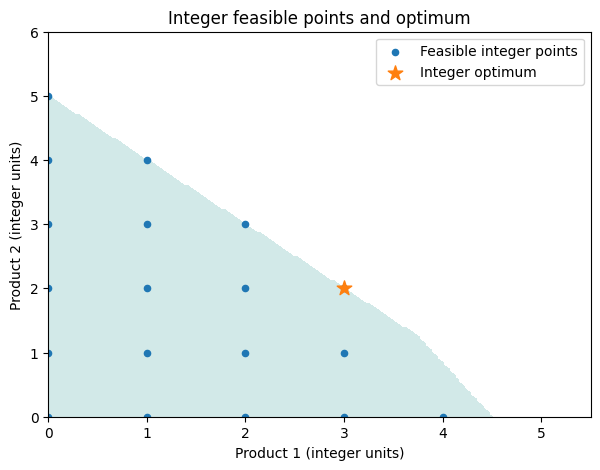

In [10]:
def bb_trace():
    stack=[('N1',{})]; incumbent=-float('inf'); best=None; history=[]; nodecount=1
    while stack:
        name,bounds=stack.pop()
        bd=[bounds.get(i,(0,None)) for i in range(2)]
        lp=linprog([-5,-4],A_ub=[[1,1],[10,6]],b_ub=[5,45],bounds=bd,method='highs')
        if not lp.success:
            history.append([name,str(bounds),'—','—','Infeasible → prune']); continue
        z=-lp.fun; x=lp.x
        if z<=incumbent+1e-8:
            history.append([name,str(bounds),str(np.round(x,4)),round(z,4),'Bound ≤ incumbent → prune']);continue
        f=[j for j in range(2) if abs(x[j]-round(x[j]))>1e-7]
        if not f:
            incumbent=z;best=x.copy()
            history.append([name,str(bounds),str(np.round(x,4)),round(z,4),'Integer → update incumbent']);continue
        j=f[0]; low=int(np.floor(x[j]));high=low+1
        history.append([name,str(bounds),str(np.round(x,4)),round(z,4),f'Branch x{j+1} ≤ {low} / ≥ {high}'])
        for side,limit in [('right',high),('left',low)]:
            new=dict(bounds); l,u=new.get(j,(0,None))
            if side=='left':u=min(u,limit) if u is not None else limit
            else:l=max(l,limit)
            new[j]=(l,u);nodecount+=1
            stack.append((f'N{nodecount}',new))
    return pd.DataFrame(history,columns=['Node','Added bounds','LP solution','LP bound','Action']),best,incumbent
trace,best,val=bb_trace();display(trace)
print('B&B optimum:',best,'maximum profit:',val)
check=solve_milp([-5,-4],[[1,1],[10,6]],[-np.inf,-np.inf],[5,45])
assert np.isclose(val,-check.fun)
fig,ax=plt.subplots(figsize=(7,5))
xx=np.linspace(0,5.5,180); yy=np.linspace(0,6,180); X,Y=np.meshgrid(xx,yy)
mask=(X+Y<=5+1e-9)&(10*X+6*Y<=45+1e-9)
ax.contourf(X,Y,mask.astype(int),levels=[.5,1.5],alpha=.2)
pts=np.array([(i,j) for i in range(6) for j in range(6) if i+j<=5 and 10*i+6*j<=45])
ax.scatter(pts[:,0],pts[:,1],s=20,label='Feasible integer points')
ax.scatter([best[0]],[best[1]],s=120,marker='*',label='Integer optimum')
ax.set(xlabel='Product 1 (integer units)',ylabel='Product 2 (integer units)',title='Integer feasible points and optimum',xlim=(0,5.5),ylim=(0,6))
ax.legend();plt.show()

### Branch-and-bound — numerical tests at every node

For every processed node, compute the LP upper bound $U_N=5x_1^{LP}+4x_2^{LP}$ and compare it to the current best integer objective $z_{\mathrm{inc}}$. If $U_N\le z_{\mathrm{inc}}$, prune because no descendant can improve the incumbent. Otherwise, if $x_j^{LP}$ is fractional, calculate **both** branch limits $\lfloor x_j^{LP}\rfloor$ and $\lceil x_j^{LP}\rceil$. The next output repeats the node exploration with individual resource consumption, feasibility tests, branching thresholds and incumbent changes visible.

**Important:** The LP objective is an *upper bound*, not an implementable profit until an integer-feasible point is found.

In [11]:
node_records=[]; pending=[('N1',{})]; incumbent=-np.inf; next_id=1
while pending:
    node,bounds_map=pending.pop()
    lpnode=linprog([-5,-4],A_ub=[[1,1],[10,6]],b_ub=[5,45],
        bounds=[bounds_map.get(i,(0,None)) for i in range(2)],method='highs')
    old=incumbent
    if not lpnode.success:
        node_records.append([node,str(bounds_map),'—','—','—','—',old if np.isfinite(old) else '—','Infeasible; prune'])
        continue
    x=lpnode.x; obj=-lpnode.fun; r1=x.sum();r2=10*x[0]+6*x[1]
    frac=[j for j in range(2) if abs(x[j]-round(x[j]))>1e-7]
    if obj<=incumbent+1e-8:decision=f'{obj:.4f} ≤ {incumbent:.4f}; prune by bound'
    elif not frac:incumbent=obj;decision=f'Both integer; incumbent ← {obj:.4f}'
    else:
        j=frac[0];lo=int(np.floor(x[j]));hi=lo+1
        decision=f'x{j+1}={x[j]:.4f} fractional; create x{j+1}≤{lo} and x{j+1}≥{hi}'
        for side,limit in [('right',hi),('left',lo)]:
            bnew=dict(bounds_map); lb,ub=bnew.get(j,(0,None))
            if side=='left':ub=min(ub,limit) if ub is not None else limit
            else:lb=max(lb,limit)
            bnew[j]=(lb,ub);next_id+=1;pending.append((f'N{next_id}',bnew))
    node_records.append([node,str(bounds_map),tuple(np.round(x,4)),round(obj,4),round(r1,4),round(r2,4),
        round(old,4) if np.isfinite(old) else '—',decision])
display(pd.DataFrame(node_records,columns=['Node','Restrictions','LP (x1,x2)','U = 5x1+4x2','x1+x2 (≤5)','10x1+6x2 (≤45)','Incumbent before','Calculation and decision']))
assert np.isclose(incumbent,val)


,Node,Restrictions,"LP (x1,x2)",U = 5x1+4x2,x1+x2 (≤5),10x1+6x2 (≤45),Incumbent before,Calculation and decision
0,N1,{},"(3.75, 1.25)",23.75,5.0,45.0,—,x1=3.7500 fractional; create x1≤3 and x1≥4
1,N3,"{0: (0, 3)}","(3.0, 2.0)",23.0,5.0,42.0,—,Both integer; incumbent ← 23.0000
2,N2,"{0: (4, None)}","(4.0, 0.8333)",23.3333,4.8333,45.0,23.0,x2=0.8333 fractional; create x2≤0 and x2≥1
3,N5,"{0: (4, None), 1: (0, 0)}","(4.5, 0.0)",22.5,4.5,45.0,23.0,22.5000 ≤ 23.0000; prune by bound
4,N4,"{0: (4, None), 1: (1, None)}",—,—,—,—,23.0,Infeasible; prune


## 6. Cutting planes — a complete Gomory example

**Problem.** A small factory produces two indivisible products with profit 3 and 2 per unit. The machine has five resource units available, and each product consumes two resource units:

$$
\max z=3x_1+2x_2,\qquad 2x_1+2x_2\le5,\qquad x_1,x_2\in\mathbb Z_{\ge0}.
$$

After adding the integer slack $s\ge0$:

$$
2x_1+2x_2+s=5.
$$

The LP relaxation chooses $x_1=2.5$, $x_2=0$, obtaining $z_{LP}=7.5$. The basic-row representation is

$$
x_1=\frac52-x_2-\frac12s.
$$

The Gomory fractional-cut construction takes fractional parts of the nonbasic coefficients:

$$
\frac12s\ge\frac12\quad\Longleftrightarrow\quad s\ge1.
$$

Substituting $s=5-2x_1-2x_2$ yields the valid integer restriction:

$$
x_1+x_2\le2.
$$

**Algorithm.** Solve the LP relaxation; identify a tableau row with fractional basic RHS; derive a cut satisfied by all integer solutions but violated by the current fractional optimum; add the cut; re-optimize. Repeat until integrality is achieved or switch to branching. This example finishes with **one cut**, whose validity is verified by enumerating feasible integer points. General cut generation requires careful tableau arithmetic, row signs, and numerical tolerances.

### Gomory fractional cutting plane

**PSEUDOCODE — executable algorithm logic**

The pure-integer Gomory fractional-cut method starts from an *optimal simplex tableau* of the LP relaxation, not merely an arbitrary fractional solution. For a basic row written as

$$
x_{B_i}=b_i-\sum_{j\in N}a_{ij}x_j,
$$

where all variables in the row are integer-constrained, let $f(t)=t-\lfloor t\rfloor$. If $f(b_i)>0$, the fractional cut is

$$
\sum_{j\in N}f(a_{ij})x_j\ge f(b_i).
$$

```text
# PSEUDOCODE (NOT PYTHON)
GOMORY_FRACTIONAL_CUTS(integer_LP):
    relax integrality and solve using simplex
    while the LP optimum has fractional integer basic variables:
        choose an optimal tableau row with fractional RHS b_i
        if the selected row is not a valid pure-integer tableau row:
            use an appropriate mixed-integer cut procedure instead
        compute fractional parts f(b_i) and f(a_ij)
        construct cut: sum(f(a_ij) * x_j) >= f(b_i)
        append cut to current LP
        re-optimize LP, preferably warm-starting with dual simplex
        stop/report if infeasible or a numerical safeguard is triggered
    return an integer-feasible optimum when obtained
```

**Worked example:** the tableau row $x_1=5/2-x_2-s/2$ has fractional right-hand side $1/2$. Since $f(1)=0$ and $f(1/2)=1/2$, the cut is $s/2\ge1/2$. Substituting $s=5-2x_1-2x_2$ yields $x_1+x_2\le2$. The code then re-solves the LP and verifies the resulting integer optimum. This is a one-cut demonstration, not a generic industrial cutting-plane implementation.

### Gomory cut — every numerical calculation

**Step 1 — LP relaxation.** Drop integrality. At the LP optimum, $x_1=2.5$, $x_2=0$, $s=0$, and $z=3(2.5)+2(0)=7.5$.

**Step 2 — Fractional basic row.** Divide the binding constraint by 2 and isolate the basic variable:

$$
x_1=2.5-x_2-0.5s.
$$

**Step 3 — Compute fractional parts.** The RHS fractional part is $f(2.5)=0.5$, while $f(1)=0$ and $f(0.5)=0.5$. Thus:

$$
0x_2+0.5s\ge0.5.
$$

**Step 4 — Eliminate the slack.** Since $s=5-2x_1-2x_2$:

$$
0.5(5-2x_1-2x_2)\ge0.5
\quad\Longrightarrow\quad x_1+x_2\le2.
$$

**Step 5 — Reoptimize.** Add $x_1+x_2\le2$ to the LP; the optimum becomes $x_1=2$, $x_2=0$, $z=6$ (integer).

**Step 6 — Verify validity.** Each integer feasible point satisfies $x_1+x_2\le\lfloor 5/2\rfloor=2$. The fractional former optimum $x_1=2.5$ violates the cut and is eliminated. Since the reoptimized LP solution is integral, this example terminates after exactly one cut.

In [12]:
A=[[2,2]];rhs=[5]
pre=linprog([-3,-2],A_ub=A,b_ub=rhs,bounds=[(0,None)]*2,method='highs')
post=linprog([-3,-2],A_ub=[[2,2],[1,1]],b_ub=[5,2],bounds=[(0,None)]*2,method='highs')
exact=solve_milp([-3,-2],A,[-np.inf],rhs)
print('LP before cut:',pre.x,'profit:',-pre.fun,'slack:',5-2*sum(pre.x))
print('LP after Gomory cut:',post.x,'profit:',-post.fun)
print('Integer solution:',exact.x,'profit:',-exact.fun)
for i in range(3):
    for j in range(3):
        if 2*i+2*j<=5: assert i+j<=2
assert np.isclose(-post.fun,-exact.fun)

LP before cut: [2.5 0. ] profit: 7.5 slack: 0.0
LP after Gomory cut: [2. 0.] profit: 6.0
Integer solution: [2. 0.] profit: 6.0


### Full cutting-plane iteration table and integer-validity check

The cut process has six explicit operations: (1) solve the relaxation, (2) select a fractional basic row, (3) take coefficient/RHS fractional parts, (4) express the cut in original variables, (5) add it to the LP, (6) repeat the integrality check. This particular problem needs **exactly one cut**, not multiple cuts; no iterations are omitted. The following table checks the cut against **every feasible integer production combination** in this bounded example.

In [13]:
gomory_steps=pd.DataFrame([
    [0,'LP without cuts','x1=2.5, x2=0, s=0','z=3(2.5)+2(0)=7.5','Fractional x1; continue'],
    [1,'Basic row','x1=2.5−x2−0.5s','RHS fractional part 0.5','Generate cut'],
    [2,'Gomory fractional cut','0.5s ≥ 0.5','Multiply by 2: s ≥ 1','Fractional LP optimum violates cut'],
    [3,'Substitute s=5−2x1−2x2','0.5(5−2x1−2x2) ≥ 0.5','x1+x2 ≤ 2','Append cut'],
    [4,'Re-solve LP with cut','x1=2, x2=0','z=3(2)+2(0)=6','All required variables integer; STOP']
],columns=['Step','Operation','Numerical calculation','Derived value','Decision'])
display(gomory_steps)
integer_points=[]
for i in range(3):
    for j in range(3):
        if 2*i+2*j<=5:
            integer_points.append([i,j,2*i+2*j,i+j,i+j<=2,3*i+2*j])
display(pd.DataFrame(integer_points,columns=['x1','x2','Used resource','x1+x2','Cut satisfied','Profit']))
assert all(row[4] for row in integer_points)


,Step,Operation,Numerical calculation,Derived value,Decision
0,0,LP without cuts,"x1=2.5, x2=0, s=0",z=3(2.5)+2(0)=7.5,Fractional x1; continue
1,1,Basic row,x1=2.5−x2−0.5s,RHS fractional part 0.5,Generate cut
2,2,Gomory fractional cut,0.5s ≥ 0.5,Multiply by 2: s ≥ 1,Fractional LP optimum violates cut
3,3,Substitute s=5−2x1−2x2,0.5(5−2x1−2x2) ≥ 0.5,x1+x2 ≤ 2,Append cut
4,4,Re-solve LP with cut,"x1=2, x2=0",z=3(2)+2(0)=6,All required variables integer; STOP


,x1,x2,Used resource,x1+x2,Cut satisfied,Profit
0,0,0,0,0,True,0
1,0,1,2,1,True,2
2,0,2,4,2,True,4
3,1,0,2,1,True,3
4,1,1,4,2,True,5
5,2,0,4,2,True,6


## 7. Traveling Salesperson Problem (TSP) — route selection

**Problem.** A service vehicle starts at city A, visits B, C, D, E exactly once, and returns to A. Each pair of cities has the travel cost in the symmetric matrix below (illustrative units). Find a minimum-cost closed tour.

| City | A | B | C | D | E |
|---|---:|---:|---:|---:|---:|
| A | 0 | 14 | 9 | 16 | 18 |
| B | 14 | 0 | 11 | 7 | 12 |
| C | 9 | 11 | 0 | 10 | 13 |
| D | 16 | 7 | 10 | 0 | 8 |
| E | 18 | 12 | 13 | 8 | 0 |

Let $x_{ij}=1$ when the vehicle travels directly from city $i$ to city $j$; otherwise $x_{ij}=0$. Each city needs one incoming and one outgoing edge. Subtour-elimination constraints are required, since degree constraints alone can create disconnected cycles.

$$
\min z=\sum_{i=1}^{5}\sum_{j\ne i}d_{ij}x_{ij}
$$

$$
\sum_{j\ne i}x_{ij}=1\quad(i=1,\ldots,5),\qquad
\sum_{i\ne j}x_{ij}=1\quad(j=1,\ldots,5).
$$

For five cities, the **individual departure equations** are:

$$
\begin{aligned}
x_{12}+x_{13}+x_{14}+x_{15}&=1\\
x_{21}+x_{23}+x_{24}+x_{25}&=1\\
x_{31}+x_{32}+x_{34}+x_{35}&=1\\
x_{41}+x_{42}+x_{43}+x_{45}&=1\\
x_{51}+x_{52}+x_{53}+x_{54}&=1
\end{aligned}
$$

The **individual arrival equations** are:

$$
\begin{aligned}
x_{21}+x_{31}+x_{41}+x_{51}&=1\\
x_{12}+x_{32}+x_{42}+x_{52}&=1\\
x_{13}+x_{23}+x_{43}+x_{53}&=1\\
x_{14}+x_{24}+x_{34}+x_{54}&=1\\
x_{15}+x_{25}+x_{35}+x_{45}&=1
\end{aligned}
$$

For this example the fully expanded transportation-cost objective is:

$$
\begin{aligned}
\min z={}&14x_{12}+9x_{13}+16x_{14}+18x_{15}\\
&+14x_{21}+11x_{23}+7x_{24}+12x_{25}\\
&+9x_{31}+11x_{32}+10x_{34}+13x_{35}\\
&+16x_{41}+7x_{42}+10x_{43}+8x_{45}\\
&+18x_{51}+12x_{52}+13x_{53}+8x_{54}.
\end{aligned}
$$

Using Miller–Tucker–Zemlin order variables $u_2,\ldots,u_5$:

$$
u_i-u_j+5x_{ij}\le4,\quad i,j\in\{2,3,4,5\},\ i\ne j,
$$

$$
1\le u_i\le4,\qquad x_{ij}\in\{0,1\}.
$$

**Algorithm 1: nearest neighbor.** Starting at A, repeatedly visit the closest unvisited city; close the tour at A. Print the candidates and selected edge at each step. This is fast but **not guaranteed optimal**.

**Algorithm 2: 2-opt.** Repeatedly reverse a consecutive subsequence of the tour whenever doing so decreases total cost. Print every accepted move and stop when no improving reversal remains.

**Algorithm 3: branch-and-bound.** Construct tours incrementally, maintaining the current partial cost. Compute a valid lower bound by adding the minimum cost of completing the remaining path; prune if it cannot beat the best full tour. Print every visited/pruned state. An exhaustive permutation check verifies optimality for five cities.

### Nearest-neighbor and 2-opt — algorithms and pseudocode

**Nearest neighbor** constructs one feasible tour. At each step, select the nearest *unvisited* city from the current city and finally return to the start. Ties require a consistent rule, such as the smallest city index.

```text
NEAREST_NEIGHBOR(distance, start):
    route <- [start]
    unvisited <- all cities except start
    while unvisited is not empty:
        current <- last city in route
        next <- city in unvisited minimizing distance[current, city]
        append next to route
        remove next from unvisited
    append start to close the tour
    return route, route_cost
```

**2-opt** is a local search that attempts to remove two tour edges and reconnect the route by reversing the intervening segment. The procedure must test candidate reversals; stopping means *2-opt local optimality*, not necessarily global optimality.

```text
TWO_OPT(distance, initial_tour):
    best <- initial_tour
    repeat:
        improved <- false
        for each valid pair of reversal indices (i, k):
            candidate <- tour with segment i..k reversed
            if cost(candidate) < cost(best) - tolerance:
                best <- candidate
                improved <- true
                break                         # first-improvement variant
        if not improved:
            return best, cost(best)
```

**Iteration interpretation:** print the current city, its unvisited candidates and chosen edge for nearest neighbor; for 2-opt, display the old and new tour costs for each accepted reversal. The next cell implements both and compares their routes.

In [14]:
D=np.array([[0,14,9,16,18],[14,0,11,7,12],[9,11,0,10,13],
            [16,7,10,0,8],[18,12,13,8,0]])
ncity=5; names=list('ABCDE')
def tourcost(t):
    return int(sum(D[t[i],t[i+1]] for i in range(len(t)-1)))
def showtour(t):
    return ' → '.join(names[k] for k in t)

# Nearest neighbor: EVERY selection step, including all candidate distances.
route=[0]; todo=set(range(1,ncity)); steps=[]; cumulative=0
while todo:
    cur=route[-1]
    candidates=sorted([(int(D[cur,j]),j) for j in todo],key=lambda t:(t[0],t[1]))
    edge_cost,j=candidates[0]
    cumulative+=edge_cost
    steps.append([len(steps)+1,names[cur],', '.join(f'{names[v]}:{c}' for c,v in candidates),
                  names[j],edge_cost,cumulative])
    route.append(j); todo.remove(j)
last_cost=int(D[route[-1],0]); cumulative+=last_cost
steps.append([len(steps)+1,names[route[-1]],f'A:{last_cost}', 'A',last_cost,cumulative])
route.append(0)
print('NEAREST NEIGHBOR — EVERY DECISION')
display(pd.DataFrame(steps,columns=['Step','Current city','Candidate edges (cost)','Selected','Edge cost','Running cost']))
print('Nearest-neighbor tour:',showtour(route),'total cost:',tourcost(route))

# Best-improvement 2-opt: DISPLAY EVERY candidate, not only accepted improvements.
all_tests=[]; accepted=[]; curr=route[:]; iteration=0
while True:
    iteration+=1
    candidate_moves=[]
    for i in range(1,ncity-1):
        for k in range(i+1,ncity):
            cand=curr[:i]+curr[i:k+1][::-1]+curr[k+1:]
            cost=tourcost(cand); delta=cost-tourcost(curr)
            all_tests.append([iteration,showtour(curr),i,k,showtour(cand),tourcost(curr),cost,delta])
            if delta<0: candidate_moves.append((cost,i,k,cand))
    if not candidate_moves:
        print(f'2-opt iteration {iteration}: no negative Δ; local optimum reached.')
        break
    new_cost,i,k,new=min(candidate_moves,key=lambda t:(t[0],t[1],t[2]))
    accepted.append([iteration,showtour(curr),f'Reverse {i}–{k}',showtour(new),tourcost(curr),new_cost])
    curr=new
print('2-OPT — EVERY CANDIDATE REVERSAL, INCLUDING REJECTIONS')
display(pd.DataFrame(all_tests,columns=['Pass','Current tour','i','k','Candidate tour','Old cost','New cost','Δ = new−old']))
print('2-OPT — ACCEPTED IMPROVEMENTS')
display(pd.DataFrame(accepted,columns=['Pass','Old route','Move','New route','Old cost','New cost']))
print('Final 2-opt tour:',showtour(curr),'cost:',tourcost(curr))


NEAREST NEIGHBOR — EVERY DECISION


,Step,Current city,Candidate edges (cost),Selected,Edge cost,Running cost
0,1,A,"C:9, B:14, D:16, E:18",C,9,9
1,2,C,"D:10, B:11, E:13",D,10,19
2,3,D,"B:7, E:8",B,7,26
3,4,B,E:12,E,12,38
4,5,E,A:18,A,18,56


Nearest-neighbor tour: A → C → D → B → E → A total cost: 56
2-opt iteration 3: no negative Δ; local optimum reached.
2-OPT — EVERY CANDIDATE REVERSAL, INCLUDING REJECTIONS


,Pass,Current tour,i,k,Candidate tour,Old cost,New cost,Δ = new−old
0,1,A → C → D → B → E → A,1,2,A → D → C → B → E → A,56,67,11
1,1,A → C → D → B → E → A,1,3,A → B → D → C → E → A,56,62,6
2,1,A → C → D → B → E → A,1,4,A → E → B → D → C → A,56,56,0
3,1,A → C → D → B → E → A,2,3,A → C → B → D → E → A,56,53,-3
4,1,A → C → D → B → E → A,2,4,A → C → E → B → D → A,56,57,1
5,1,A → C → D → B → E → A,3,4,A → C → D → E → B → A,56,53,-3
6,2,A → C → B → D → E → A,1,2,A → B → C → D → E → A,53,61,8
7,2,A → C → B → D → E → A,1,3,A → D → B → C → E → A,53,65,12
8,2,A → C → B → D → E → A,1,4,A → E → D → B → C → A,53,53,0
9,2,A → C → B → D → E → A,2,3,A → C → D → B → E → A,53,56,3


2-OPT — ACCEPTED IMPROVEMENTS


,Pass,Old route,Move,New route,Old cost,New cost
0,1,A → C → D → B → E → A,Reverse 2–3,A → C → B → D → E → A,56,53
1,2,A → C → B → D → E → A,Reverse 2–4,A → C → E → D → B → A,53,51


Final 2-opt tour: A → C → E → D → B → A cost: 51


### 2-opt — explain every edge exchange numerically

When positions $i$ through $k$ are reversed, the current tour removes the edges $(a,b)$ and $(c,d)$ and inserts $(a,c)$ and $(b,d)$, where $a=	ext{tour}[i-1]$, $b=	ext{tour}[i]$, $c=	ext{tour}[k]$, and $d=	ext{tour}[k+1]$. For symmetric distances, the interior reversed edges have unchanged cost. Therefore

$$
\Delta=d_{a,c}+d_{b,d}-d_{a,b}-d_{c,d}.
$$

A negative $\Delta$ improves the tour. The code below shows the **four edge costs for every attempted reversal**, including moves that are rejected. At each pass, choose the greatest decrease (best improvement). Stop once no tested reversal reduces cost.

In [15]:
edge_tests=[]; test_route=route[:]; p=0
while True:
    p+=1; viable=[]
    for i in range(1,ncity-1):
        for k in range(i+1,ncity):
            a,b,c,d=test_route[i-1],test_route[i],test_route[k],test_route[k+1]
            old_edges=int(D[a,b]+D[c,d]);new_edges=int(D[a,c]+D[b,d]); delta=new_edges-old_edges
            trial=test_route[:i]+test_route[i:k+1][::-1]+test_route[k+1:]
            assert delta==tourcost(trial)-tourcost(test_route)
            edge_tests.append([p,f'{names[a]}–{names[b]}',f'{names[c]}–{names[d]}',
              f'{names[a]}–{names[c]}',f'{names[b]}–{names[d]}',old_edges,new_edges,delta,
              tourcost(test_route),tourcost(trial),'Improves' if delta<0 else 'Reject'])
            if delta<0:viable.append((tourcost(trial),i,k,trial))
    if not viable:break
    test_route=min(viable,key=lambda q:(q[0],q[1],q[2]))[-1]
display(pd.DataFrame(edge_tests,columns=['Pass','Remove edge 1','Remove edge 2','Add edge 1','Add edge 2',
 'Old edge costs','New edge costs','Δ','Tour before','Tour after','Decision']))
assert test_route==curr


,Pass,Remove edge 1,Remove edge 2,Add edge 1,Add edge 2,Old edge costs,New edge costs,Δ,Tour before,Tour after,Decision
0,1,A–C,D–B,A–D,C–B,16,27,11,56,67,Reject
1,1,A–C,B–E,A–B,C–E,21,27,6,56,62,Reject
2,1,A–C,E–A,A–E,C–A,27,27,0,56,56,Reject
3,1,C–D,B–E,C–B,D–E,22,19,-3,56,53,Improves
4,1,C–D,E–A,C–E,D–A,28,29,1,56,57,Reject
5,1,D–B,E–A,D–E,B–A,25,22,-3,56,53,Improves
6,2,A–C,B–D,A–B,C–D,16,24,8,53,61,Reject
7,2,A–C,D–E,A–D,C–E,17,29,12,53,65,Reject
8,2,A–C,E–A,A–E,C–A,27,27,0,53,53,Reject
9,2,C–B,D–E,C–D,B–E,19,22,3,53,56,Reject


### Exact B&B tour trace

At a partial route ending at city $v$, all unvisited cities must still be included before returning to A. A safe, inexpensive bound is

$$
L=\text{cost so far}+\min_{j\in U}d_{vj}+\operatorname{MST}(U)+\min_{j\in U}d_{jA},
$$

where $U$ is the set of unvisited cities and $\operatorname{MST}(U)$ is the minimum spanning-tree cost connecting them. For $U=\varnothing$, use the direct return edge $d_{vA}$. The bound cannot exceed the cost of any completion, so pruning is safe. The following trace prints each examined partial route and its action.

### Exact traveling-salesperson branch-and-bound

**PSEUDOCODE — executable algorithm logic**

**State:** a partial path beginning at A, its visited cities, and accumulated travel cost. **Incumbent:** the shortest complete tour found. **Lower bound:** partial cost plus a provable minimum completion cost (the connecting-edge/MST expression below). **Pruning:** a state is discarded if its lower bound is no better than the incumbent.

```text
# PSEUDOCODE (NOT PYTHON)
TSP_BRANCH_AND_BOUND(distance, start):
    best_cost <- infinity
    best_tour <- none
    open_states <- [(route=[start], cost_so_far=0)]
    while open_states is not empty:
        state <- remove one state
        remaining <- cities not in state.route
        lower_bound <- SAFE_COMPLETION_BOUND(state, remaining)
        if lower_bound >= best_cost - tolerance:
            record PRUNED_BY_BOUND
            continue
        if remaining is empty:
            total <- state.cost_so_far + distance[last_city, start]
            if total < best_cost:
                best_cost <- total
                best_tour <- state.route followed by start
            record COMPLETE_TOUR
            continue
        for each next_city in remaining:
            new_cost <- state.cost_so_far + distance[last_city, next_city]
            add (extended_route, new_cost) to open_states
            record EXPANDED
    return best_tour, best_cost
```

The bound and the full search trace appear below. The following program also compares the result with exhaustive enumeration to verify optimality for this five-city instance.

TSP BRANCH-AND-BOUND — EVERY VISITED STATE AND THE CALCULATION OF ITS LOWER BOUND


,Partial route,Unvisited,Cost so far,Min outgoing,MST,Min return,Lower bound,Incumbent before,Decision
0,A,"B,C,D,E",0,9,25.0,9,43.0,56,Branch into remaining cities
1,A → C,"B,D,E",9,10,15.0,14,48.0,56,Branch into remaining cities
2,A → C → D,"B,E",19,7,12.0,14,52.0,56,Branch into remaining cities
3,A → C → D → B,E,26,12,0.0,18,56.0,56,Pruned: lower bound ≥ incumbent
4,A → C → D → E,B,27,12,0.0,14,53.0,56,Branch into remaining cities
5,A → C → D → E → B,—,39,0,0.0,14,53.0,56,Complete tour: improve incumbent
6,A → C → B,"D,E",20,7,8.0,16,51.0,53,Branch into remaining cities
7,A → C → B → D,E,27,8,0.0,18,53.0,53,Pruned: lower bound ≥ incumbent
8,A → C → B → E,D,32,8,0.0,16,56.0,53,Pruned: lower bound ≥ incumbent
9,A → C → E,"B,D",22,8,7.0,14,51.0,53,Branch into remaining cities


Exact optimum: A → C → E → D → B → A cost: 51
Exhaustive verification: 24 anchored tours, best cost 51


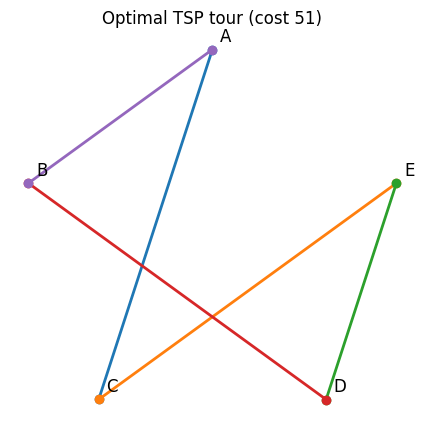

In [16]:
from scipy.sparse.csgraph import minimum_spanning_tree
from itertools import permutations

def bound_components(path, remaining):
    cost_so_far = sum(int(D[path[t],path[t+1]]) for t in range(len(path)-1))
    if not remaining:
        return cost_so_far, 0, 0, int(D[path[-1],0]), cost_so_far + int(D[path[-1],0])
    rem=sorted(remaining)
    connect_from_last=min(int(D[path[-1],j]) for j in rem)
    mst_cost=0 if len(rem)==1 else float(minimum_spanning_tree(D[np.ix_(rem,rem)]).sum())
    return_to_start=min(int(D[j,0]) for j in rem)
    lower=cost_so_far+connect_from_last+mst_cost+return_to_start
    return cost_so_far,connect_from_last,mst_cost,return_to_start,lower

def bound(path,remaining):
    return bound_components(path,remaining)[-1]

bestcost=tourcost(route);besttour=route[:]; states=[]
def search(path,remain):
    global bestcost,besttour
    components=bound_components(path,remain)
    partial,connect,mst,return_edge,L=components
    incumbent_before=bestcost
    if L>=bestcost-1e-9:
        action='Pruned: lower bound ≥ incumbent'
    elif not remain:
        action='Complete tour: improve incumbent'
    else:
        action='Branch into remaining cities'
    states.append([showtour(path),','.join(names[j] for j in sorted(remain)) or '—',
                   partial,connect,mst,return_edge,round(L,3),incumbent_before,action])
    if L>=bestcost-1e-9:return
    if not remain:
        if L<bestcost:bestcost=L;besttour=path+[0]
        return
    for j in sorted(remain,key=lambda j:(D[path[-1],j],j)):
        search(path+[j],remain-{j})
search([0],set(range(1,ncity)))
print('TSP BRANCH-AND-BOUND — EVERY VISITED STATE AND THE CALCULATION OF ITS LOWER BOUND')
display(pd.DataFrame(states,columns=['Partial route','Unvisited','Cost so far','Min outgoing','MST','Min return','Lower bound','Incumbent before','Decision']))
all_tours=[([0]+list(p)+[0],tourcost([0]+list(p)+[0])) for p in permutations(range(1,ncity))]
exact_cost=min(v for _,v in all_tours)
assert exact_cost==bestcost
print('Exact optimum:',showtour(besttour),'cost:',bestcost)
print('Exhaustive verification:',len(all_tours),'anchored tours, best cost',exact_cost)
fig,ax=plt.subplots(figsize=(7,5))
angles=np.linspace(0,2*np.pi,ncity,endpoint=False)+np.pi/2
pos=np.c_[np.cos(angles),np.sin(angles)]
for a,b in zip(besttour[:-1],besttour[1:]):
    ax.plot([pos[a,0],pos[b,0]],[pos[a,1],pos[b,1]],'-o',linewidth=2)
for i,(x,y) in enumerate(pos):ax.text(x+0.04,y+.04,names[i],fontsize=12)
ax.set_title(f'Optimal TSP tour (cost {bestcost})');ax.set_aspect('equal');ax.axis('off');plt.show()


### TSP branch-and-bound — every lower-bound term and child expansion

At each partial route, the safe lower bound is the sum of **four separately calculated terms**: accumulated edge cost, cheapest outgoing edge from the last city to an unvisited city, MST cost on unvisited cities, and cheapest edge back to A. If no city remains, the completion bound is simply accumulated cost plus the final return edge. The full table above lists every visited partial route, including those pruned. The following audit expands its calculations into readable arithmetic and reports the number of branches excluded by a bound.

In [17]:
tsp_audit=[]
for row in states:
    path,unvis,partial,out,mst,ret,lb,inc,action=row
    expression=f'{partial:g} + {out:g} + {mst:g} + {ret:g} = {lb:g}'
    tsp_audit.append([path,unvis,expression,inc,action])
display(pd.DataFrame(tsp_audit,columns=['Partial route','Remaining cities','Bound calculation (partial + outgoing + MST + return)','Incumbent before','Decision']))
print('Nodes examined:',len(states),'Pruned by bound:',sum('Pruned' in row[-1] for row in states),
      'Expanded:',sum('Branch' in row[-1] for row in states))
assert min(c for _,c in all_tours)==bestcost


,Partial route,Remaining cities,Bound calculation (partial + outgoing + MST + return),Incumbent before,Decision
0,A,"B,C,D,E",0 + 9 + 25 + 9 = 43,56,Branch into remaining cities
1,A → C,"B,D,E",9 + 10 + 15 + 14 = 48,56,Branch into remaining cities
2,A → C → D,"B,E",19 + 7 + 12 + 14 = 52,56,Branch into remaining cities
3,A → C → D → B,E,26 + 12 + 0 + 18 = 56,56,Pruned: lower bound ≥ incumbent
4,A → C → D → E,B,27 + 12 + 0 + 14 = 53,56,Branch into remaining cities
5,A → C → D → E → B,—,39 + 0 + 0 + 14 = 53,56,Complete tour: improve incumbent
6,A → C → B,"D,E",20 + 7 + 8 + 16 = 51,53,Branch into remaining cities
7,A → C → B → D,E,27 + 8 + 0 + 18 = 53,53,Pruned: lower bound ≥ incumbent
8,A → C → B → E,D,32 + 8 + 0 + 16 = 56,53,Pruned: lower bound ≥ incumbent
9,A → C → E,"B,D",22 + 8 + 7 + 14 = 51,53,Branch into remaining cities


Nodes examined: 19 Pruned by bound: 9 Expanded: 8


## 8. Solver validation, complexity, and model interpretation

**Integer vs. continuous decisions.** Binary site and project variables are yes/no choices; general integer production variables count indivisible items. A continuous relaxation is useful for deriving bounds even when its decisions cannot be implemented directly.

**Algorithm comparison.** Enumeration visits all combinations and scales exponentially. B&B eliminates subregions using LP or combinatorial lower/upper bounds. Cutting planes exclude fractional LP optima without excluding valid integer points. For routing, nearest neighbor is constructive, 2-opt improves a given tour, and exact B&B certifies optimality when the search is completed.

**Practical interpretation.** A mathematically valid solution must also be checked against the real scheduling, shipment, setup, and service assumptions. For instance, the fixed-charge model charges exactly once per activated provider, whereas a production setup that repeats by day requires period-specific activation variables.

**Reference:** Hamdy A. Taha, *Operations Research: An Introduction*, 8th edition, Chapter 9 (Integer Linear Programming). The project selection, receiver coverage, telephone-service, and two-variable B&B numerical data follow the chapter; the small logical module, cutting-plane, and TSP datasets are identified as illustrative examples.

### Exhaustive TSP verification

**PSEUDOCODE — executable algorithm logic**

Fixing the starting city removes rotational duplicates. Enumerate every permutation of the remaining cities, append the start to complete each tour, compute its exact cost, and keep the minimum. For five cities, this checks $(5-1)!=24$ oriented tours. It is a useful verification method for a small example, not a scalable practical routing algorithm.

```text
# PSEUDOCODE (NOT PYTHON)
ENUMERATE_TOURS(distance, start):
    best_cost <- infinity
    best_tour <- none
    for each permutation p of all cities except start:
        tour <- [start] + p + [start]
        value <- sum(distance[tour[k], tour[k+1]] for all tour edges)
        if value < best_cost:
            best_cost <- value
            best_tour <- tour
    return best_tour, best_cost
```